## model training using EfficientNetB0

import libraries and settings

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import matplotlib.pyplot as plt

In [2]:
# image resize dimensions
image_size = (224, 224)

# batch size
batch_size = 32

# dataset directory (update if needed)
dataset_path = "../dataset_8"

In [3]:
train_data_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.3,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)

validation_data_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.3
)

create training & validation generator

In [4]:
training_generator = train_data_generator.flow_from_directory(
    dataset_path,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42  # for reproducibility
)

validation_generator = validation_data_generator.flow_from_directory(
    dataset_path,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42  # for reproducibility
)

Found 336 images belonging to 4 classes.
Found 144 images belonging to 4 classes.


In [5]:
print(f"Training samples: {training_generator.samples}")
print(f"Validation samples: {validation_generator.samples}")
print(f"Number of classes: {training_generator.num_classes}")
print(f"Class indices: {training_generator.class_indices}")

Training samples: 336
Validation samples: 144
Number of classes: 4
Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


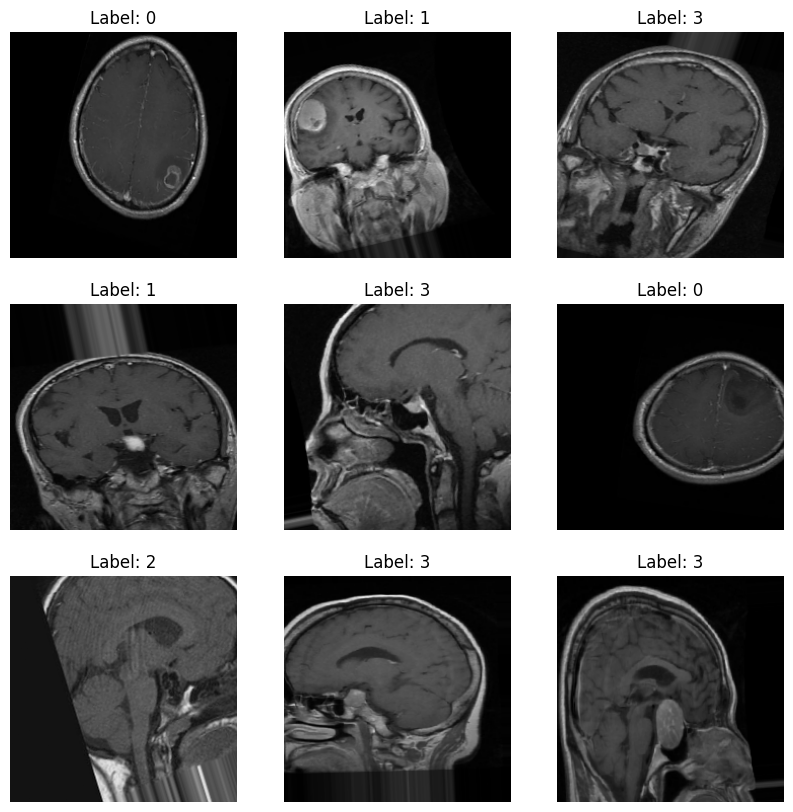

In [6]:
images, labels = next(training_generator)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i])
    plt.title(f"Label: {np.argmax(labels[i])}")
    plt.axis('off')
plt.show()

using EfficientNetB0

In [7]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# load EfficientNetB0 base model without top layers
base_model = EfficientNetB0(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # freeze base model for initial training

# build full model
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(4, activation='softmax')  # 4 output classes for dataset
])

# compile model
model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,055 (16.08 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [8]:
early_stop = EarlyStopping(patience=5, restore_best_weights=True)

history = model.fit(
    training_generator,
    epochs=20,
    validation_data=validation_generator,
    callbacks=[early_stop]
)

c:\Users\user\Desktop\csc3109-ml_project\venv\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.2650 - loss: 1.3928 - val_accuracy: 0.2500 - val_loss: 1.3871
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.2417 - loss: 1.3902 - val_accuracy: 0.2500 - val_loss: 1.3894
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.2690 - loss: 1.3841 - val_accuracy: 0.2500 - val_loss: 1.3881
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.1881 - loss: 1.3922 - val_accuracy: 0.2500 - val_loss: 1.3868
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.2441 - loss: 1.3940 - val_accuracy: 0.2500 - val_loss: 1.3908
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.2595 - loss: 1.3948 - val_accuracy: 0.2500 - val_loss: 1.3876
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.2864 - loss: 1.3829 - val_accuracy: 0.2500 - val_loss: 1.3871
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.1918 - loss: 1.3930 - val_accuracy: 0.2500 - val_loss:

evaluate training performance

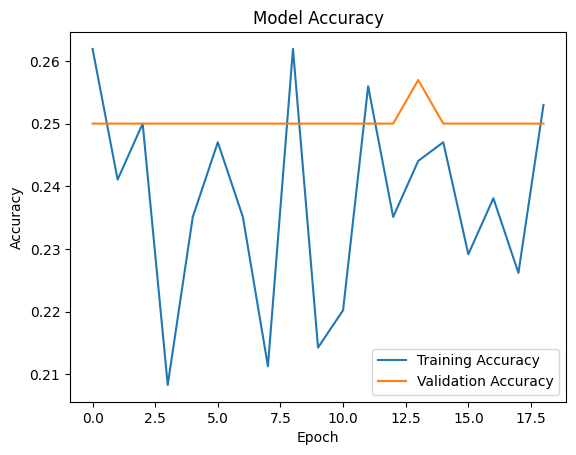

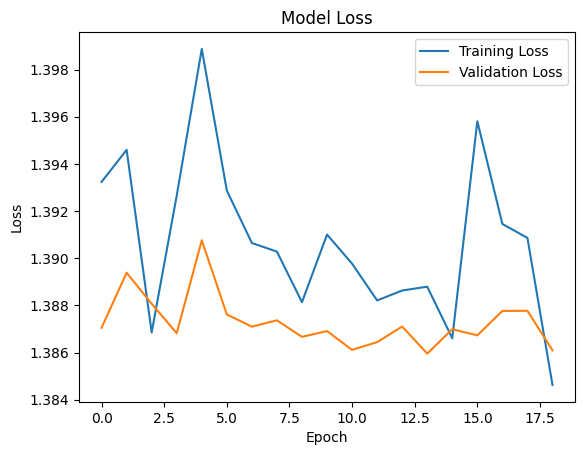

In [9]:
# plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# plot loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


### observations

even after 5-10 epochs, if validation accuracy is stuck at 25%, that's a clear sign of overfitting or poor generalization.

fine tune base model

In [10]:
base_model.trainable = True

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

early_stop = tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

history_fine = model.fit(
    training_generator,
    epochs=20,
    validation_data=validation_generator,
    callbacks=[early_stop]
)


Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 75s 4s/step - accuracy: 0.2566 - loss: 1.4093 - val_accuracy: 0.2500 - val_loss: 1.3878
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.2906 - loss: 1.3496 - val_accuracy: 0.2917 - val_loss: 1.3856
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.3696 - loss: 1.3388 - val_accuracy: 0.2431 - val_loss: 1.3855
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.3802 - loss: 1.2949 - val_accuracy: 0.2222 - val_loss: 1.3860
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.5042 - loss: 1.2478 - val_accuracy: 0.2222 - val_loss: 1.3861
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.5028 - loss: 1.2243 - val_accuracy: 0.2569 - val_loss: 1.3844
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 37s 3s/step - accuracy: 0.6193 - loss: 1.1618 - val_accuracy: 0.2917 - val_loss: 1.3838
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 34s 3s/step - accuracy: 0.5599 - loss: 1.1709 - val_accuracy: 0.2708 - val_loss:

In [11]:
print(training_generator.class_indices)
print(validation_generator.class_indices)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [12]:
val_loss, val_acc = model.evaluate(validation_generator)
print(f"Validation Accuracy: {val_acc*100:.2f}%")

5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 564ms/step - accuracy: 0.1552 - loss: 1.4076
Validation Accuracy: 26.39%


5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 986ms/step


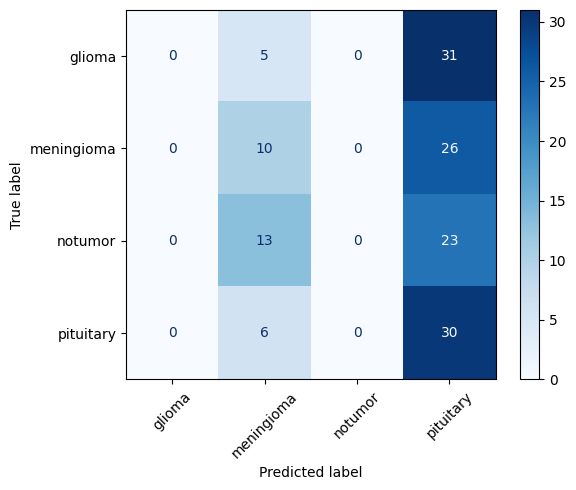

In [13]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions
Y_pred = model.predict(validation_generator)
y_pred = np.argmax(Y_pred, axis=1)

# True labels
y_true = validation_generator.classes

# Class labels in correct order
class_names = list(validation_generator.class_indices.keys())

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.show()


### observations

- model only predicts "glioma"
    - model has been overfitted/ collapsed to a single-class output
    - dataset may be too small, only 336 training images

what to do next:
- stronger data augmentation
- fine-tune base models
- consider simpler models
